# Submission Summary

| Item | Details |
|---|---|
| Group number | 01 |
| Your full name |Ebube Kingsley Ozue  |
| Dataset | Credit Risk / Loan Default |
| Depth track | Classification Depth |
| Team members | Asumu Hillary Danosi, Joy Jesutobi Gideon, Sophia Ngozi Osanebi, Igwe Chikodiri Ogbonna, Zainab Ofuje Omotosho, Williams Deborah William, Precious Oluwatosin Komolafe, Dimiari John John-Africa,Raymond Chinonso Chris, Brian Makile Mulatya, Ebube Kingsley Ozue|
| Final model | Random Forest, default settings, threshold 0.50 |
| Stratified dummy F1 / ROC AUC | 0.2061 / 0.4926 |
| Final model F1 / ROC AUC | 0.8281 / 0.9284 |
| Leakage columns dropped | None found |
| Full run time on Colab | 5.64 minutes |

In [1]:
import time
notebook_start_time = time.perf_counter()

# Part 1. Data Foundation

In [2]:
import kagglehub

# Download the dataset from Kaggle
path = kagglehub.dataset_download("laotse/credit-risk-dataset")

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'credit-risk-dataset' dataset.
Dataset downloaded to: /kaggle/input/credit-risk-dataset


In [3]:
from pathlib import Path

dataset_path = Path(path)

print("Files in the dataset folder:")
for file in dataset_path.iterdir():
    print(file.name)

Files in the dataset folder:
credit_risk_dataset.csv


In [4]:
import pandas as pd

# Load the dataset
df = pd.read_csv(dataset_path / "credit_risk_dataset.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (32581, 12)


In [5]:
# Display first five rows
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [6]:
# Checking the customer structure and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [7]:
import sqlite3

# Create a temporary SQLite database in memory
conn = sqlite3.connect(":memory:")

# Push the dataset into SQLite
df.to_sql("credit_risk", conn, if_exists="replace", index=False)

print("Dataset successfully loaded into SQLite.")

Dataset successfully loaded into SQLite.


### SQL Analysis

In [8]:
''' SQL Query 1: Default Rate by Loan Grade

We want to investigate whether loan grade is associated with loan default.
We will compare the number of loans, number of defaults, and default rate
across the different loan grades.'''

query1 = """
SELECT
    loan_grade,
    COUNT(*) AS total_loans,
    SUM(loan_status) AS defaults,
    ROUND(100.0 * AVG(loan_status), 2) AS default_rate_pct
FROM credit_risk
GROUP BY loan_grade
ORDER BY default_rate_pct DESC;
"""

result1 = pd.read_sql_query(query1, conn)
result1

,loan_grade,total_loans,defaults,default_rate_pct
0,G,64,63,98.44
1,F,241,170,70.54
2,E,964,621,64.42
3,D,3626,2141,59.05
4,C,6458,1339,20.73
5,B,10451,1701,16.28
6,A,10777,1073,9.96


<u> What we learned From the above result</u>

The SQL results show that default rates vary considerably across loan grades. Higher-risk grades generally have higher default rates, while Grade A has the lowest default rate at 9.96%. Grade G has the highest default rate at 98.44%, but it represents only 64 loans in the dataset, so this result should be interpreted with caution. Overall, loan grade appears to be an important factor associated with loan default.

In [9]:
'''SQL Query 2: Default Rate by Loan Intent
We want to investigate whether the purpose of a loan is associated with
loan default. We will compare the number of loans, number of defaults,
and default rate across the different loan intents1
'''

query2 = """
SELECT
    loan_intent,
    COUNT(*) AS total_loans,
    SUM(loan_status) AS defaults,
    ROUND(100.0 * AVG(loan_status), 2) AS default_rate_pct
FROM credit_risk
GROUP BY loan_intent
ORDER BY default_rate_pct DESC;
"""

result2 = pd.read_sql_query(query2, conn)
result2

,loan_intent,total_loans,defaults,default_rate_pct
0,DEBTCONSOLIDATION,5212,1490,28.59
1,MEDICAL,6071,1621,26.70
2,HOMEIMPROVEMENT,3605,941,26.10
3,PERSONAL,5521,1098,19.89
4,EDUCATION,6453,1111,17.22
5,VENTURE,5719,847,14.81


<u> What We Learned from the above result</u>

The SQL results show that default rates differ across loan intents. Medical loans have the highest default rate at 26.70%, followed closely by home improvement loans at 26.10%. Venture loans have the lowest default rate at 14.81%. This suggests that loan purpose may be associated with differences in default risk.

In [10]:
"""
SQL Query 3: Default Rate by Home Ownership

We want to investigate whether home ownership status is associated with loan default.
We will compare the number of loans, number of defaults, and default rate across the different home ownership categories.
"""

query3 = """
SELECT
    person_home_ownership,
    COUNT(*) AS total_loans,
    SUM(loan_status) AS defaults,
    ROUND(100.0 * AVG(loan_status), 2) AS default_rate_pct
FROM credit_risk
GROUP BY person_home_ownership
ORDER BY default_rate_pct DESC;
"""

result3 = pd.read_sql_query(query3, conn)
result3

,person_home_ownership,total_loans,defaults,default_rate_pct
0,RENT,16446,5192,31.57
1,OTHER,107,33,30.84
2,MORTGAGE,13444,1690,12.57
3,OWN,2584,193,7.47


 <u>What we learned from the above result</U>

The SQL results show that default rates differ across home ownership categories. Borrowers who rent have the highest default rate at 31.57%, while borrowers who own their homes have the lowest default rate at 7.47%. The OTHER category has a relatively high default rate of 30.84%, but it contains only 107 loans, so this result should be interpreted with caution. Overall, home ownership status appears to be associated with differences in loan default rates.

## Missing Values and Extreme Values

We first check how much data is missing in each column. This will help us decide which variables need attention later during the cleaning stage.

In [11]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [12]:
"""
We will calculate the number and percentage of missing values in each column
to understand how much data is missing before deciding how to handle it.
"""

missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary[missing_summary["missing_count"] > 0]

,missing_count,missing_percentage
person_emp_length,895,2.75
loan_int_rate,3116,9.56


In [13]:
"""
We will compare the default rate for records with missing and non-missing
values in the two affected columns. This helps us understand whether the
missingness is associated with loan default before deciding how to handle it.
"""

for column in ["person_emp_length", "loan_int_rate"]:
    print(f"\n{column}")
    print(
        df.groupby(df[column].isna())["loan_status"]
        .agg(["count", "mean"])
        .rename(index={False: "Not Missing", True: "Missing"})
        .assign(default_rate_pct=lambda x: (x["mean"] * 100).round(2))
        .drop(columns="mean")
    )


person_emp_length
                   count  default_rate_pct
person_emp_length                         
Not Missing        31686             21.54
Missing              895             31.51

loan_int_rate
               count  default_rate_pct
loan_int_rate                         
Not Missing    29465             21.94
Missing         3116             20.67


<u> What We Learned from the above result</u>

The comparison shows that records with missing `person_emp_length` have a higher default rate (31.51%) than records with non-missing values (21.54%). In contrast, the default rates for missing and non-missing `loan_int_rate` are relatively close, at 20.67% and 21.94%, respectively. This suggests that the missingness in `person_emp_length` may be associated with loan default, while the missingness in `loan_int_rate` shows little difference in default rates.

In [14]:
"""
We will examine the summary statistics of the two variables with missing
values to understand their distributions before choosing an appropriate
imputation method.
"""

df[["person_emp_length", "loan_int_rate"]].describe()

,person_emp_length,loan_int_rate
count,31686.000000,29465.000000
mean,4.789686,11.011695
std,4.142630,3.240459
min,0.000000,5.420000
25%,2.000000,7.900000
50%,4.000000,10.990000
75%,7.000000,13.470000
max,123.000000,23.220000


In [15]:
"""
We will inspect unusually high employment lengths to determine whether the
extreme values are likely to be data-entry issues that should be addressed
during cleaning.
"""

df[df["person_emp_length"] > 50][
    ["person_age", "person_emp_length", "loan_status"]
].sort_values("person_emp_length", ascending=False)

,person_age,person_emp_length,loan_status
0,22,123.0,1
210,21,123.0,0


<u> What We Learned</u>

The inspection identified two records with an employment length of 123 years. These values are not plausible given the borrowers' ages of 22 and 21 years and are therefore treated as data-entry errors. These anomalous values will need to be addressed during the data-cleaning stage rather than being used as valid employment lengths.

## Duplicate Check

Before moving on to the modelling stages, we check for exact duplicate rows. If duplicates are present, we will decide how to handle them during the cleaning stage.

In [16]:
# Count exact duplicate rows in the original dataset.
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 165


### <u>What We Learned from the above result</u>

The dataset contains 106 exact duplicate rows. These are repeated observations with the same values across all columns. We will inspect the duplicated records before deciding how to handle them during the cleaning stage.

In [17]:
# Display some of the exact duplicate records so we can inspect them
# before deciding how to handle them.

duplicate_rows = df[df.duplicated(keep=False)].sort_values(
    by=df.columns.tolist()
)

duplicate_rows.head(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
17758,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
2498,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
17601,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
1778,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
17642,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3


In [18]:
# Compare the number of duplicate rows with the number of unique
# records involved in duplication.

duplicate_summary = pd.DataFrame({
    "measure": [
        "Total rows in dataset",
        "Duplicate rows beyond their first occurrence",
        "Unique records involved in duplication"
    ],
    "count": [
        len(df),
        df.duplicated().sum(),
        duplicate_rows.drop_duplicates().shape[0]
    ]
})

duplicate_summary

,measure,count
0,Total rows in dataset,32581
1,Duplicate rows beyond their first occurrence,165
2,Unique records involved in duplication,165


<u> What we learned from the above result above</u>

 The result above shows that the duplicates are exact match so we would remove them in the data cleaning stage to get the true honest performance.

## Exporatory Data Analysis- Target and feature Distribution

In [19]:
import matplotlib.pyplot as plt

# Check the number and percentage of loans in each target class.

target_summary = pd.DataFrame({
    "count": df["loan_status"].value_counts().sort_index(),
    "percentage": (
        df["loan_status"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

target_summary.index = ["No Default (0)", "Default (1)"]

target_summary

,count,percentage
No Default (0),25473,78.18
Default (1),7108,21.82


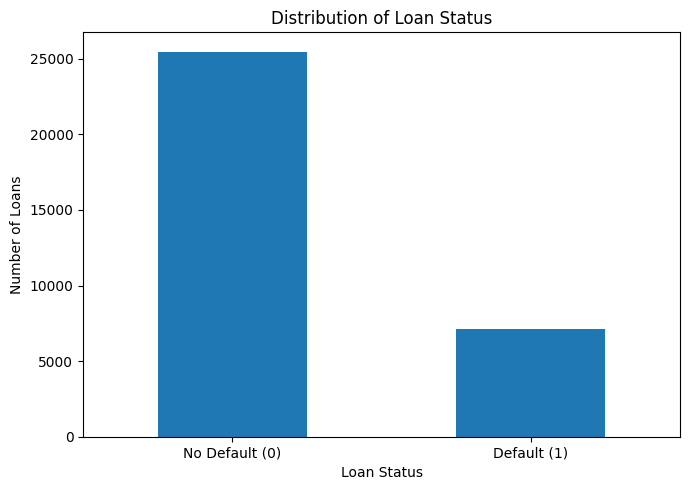

In [20]:
# Visualize the distribution of loan status.

df["loan_status"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Distribution of Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.xticks(
    ticks=[0, 1],
    labels=["No Default (0)", "Default (1)"],
    rotation=0
)

plt.tight_layout()
plt.show()

 <u>What We Learned from the above result</u>

The loan status is not evenly distributed. Most of the loans in the dataset were not in default, with 25,473 observations (78.18%), while 7,108 observations (21.82%) were defaults. This shows that the target variable is imbalanced, which we will take into account later when evaluating and improving the classification models.

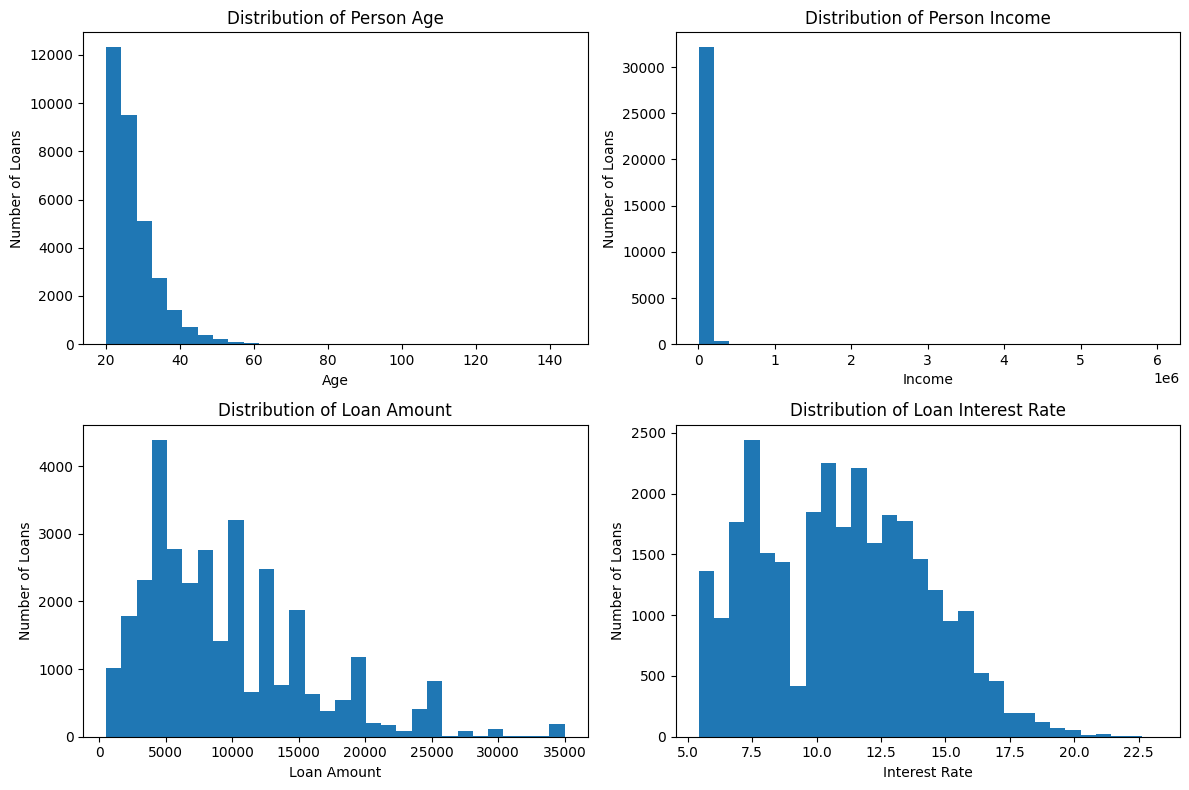

In [21]:
# Examine the distributions of four numerical variables.
# At this stage, the plots are only for understanding the data.

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df["person_age"].plot(
    kind="hist",
    bins=30,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Person Age")
axes[0, 0].set_xlabel("Age")
axes[0, 0].set_ylabel("Number of Loans")

df["person_income"].plot(
    kind="hist",
    bins=30,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of Person Income")
axes[0, 1].set_xlabel("Income")
axes[0, 1].set_ylabel("Number of Loans")

df["loan_amnt"].plot(
    kind="hist",
    bins=30,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Distribution of Loan Amount")
axes[1, 0].set_xlabel("Loan Amount")
axes[1, 0].set_ylabel("Number of Loans")

df["loan_int_rate"].plot(
    kind="hist",
    bins=30,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Distribution of Loan Interest Rate")
axes[1, 1].set_xlabel("Interest Rate")
axes[1, 1].set_ylabel("Number of Loans")

plt.tight_layout()
plt.show()

<u>What We Learned from the above result</u>

The four distributions show different patterns across the numerical variables. Person age is concentrated among younger borrowers, with a smaller number of older borrowers. Person income is strongly right-skewed, meaning most borrowers have lower incomes while a small number have much higher incomes. Loan amounts are spread across a range of values, with most loans concentrated at the lower and middle amounts. Loan interest rates are mostly concentrated between about 5% and 18%, with fewer observations at the higher rates. These patterns will be considered later when we clean and prepare the data for modelling.

In [22]:
"""
We will inspect the actual values in each categorical column.
This helps us identify unexpected labels or inconsistent entries
before the variables are encoded later.
"""

categorical_columns = df.select_dtypes(include=["object", "string"]).columns

for column in categorical_columns:
    print(f"\n{column}")
    print("-" * len(column))
    print(df[column].value_counts(dropna=False))


person_home_ownership
---------------------
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent
-----------
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade
----------
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

cb_person_default_on_file
-------------------------
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


<u>What we learned from the above result</u>

No unexpected labels or inconsistent entries where found

In [23]:
# Check for unusually high ages before deciding how to handle them.

unusual_age = df[df["person_age"] > 95][
    ["person_age", "person_income", "person_emp_length", "loan_status"]
].sort_values("person_age")

unusual_age

,person_age,person_income,person_emp_length,loan_status
747,123,78000,7.0,0
575,123,80004,2.0,0
183,144,200000,4.0,0
81,144,250000,4.0,0
32297,144,6000000,12.0,0


<u> What we learned from the result above</u>

We found 5 unrealistic person_age which we would treat as missing values.

We remove the 106 exact duplicate rows because they are repeated records, and keeping them could put the same borrower in both the training and test sets. Ages above 100 and employment lengths above 50 years are not possible, so we set them to missing instead of deleting the rows. That way we keep the rest of each borrower's information. We use 100 as the cut-off for age because only values above it are clearly impossible.

In [24]:
import numpy as np

# Keep df unchanged and create a separate dataset for cleaning.

df_clean = df.copy()

# Remove exact duplicate rows.
df_clean = df_clean.drop_duplicates().copy()

# Treat clearly unrealistic values as missing.
df_clean.loc[df_clean["person_age"] > 100, "person_age"] = np.nan
df_clean.loc[df_clean["person_emp_length"] > 50, "person_emp_length"] = np.nan

# Check the result.
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("\nMissing values after structural cleaning:")
print(df_clean[["person_age", "person_emp_length", "loan_int_rate"]].isnull().sum())

Original shape: (32581, 12)
Cleaned shape: (32416, 12)

Missing values after structural cleaning:
person_age              5
person_emp_length     889
loan_int_rate        3095
dtype: int64


In [25]:
# Separate the target variable from the predictor variables.

X = df_clean.drop(columns="loan_status")
y = df_clean["loan_status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (32416, 11)
Target shape: (32416,)


In [26]:
from sklearn.model_selection import train_test_split

# Split the data while preserving the proportion of default and non-default loans.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (25932, 11)
X_test: (6484, 11)
y_train: (25932,)
y_test: (6484,)


We fill the missing values in person_age, person_emp_length and loan_int_rate with the median from the training data only, so nothing from the test set leaks in. We use the median because these columns have outliers. One limitation is that missing person_emp_length had a higher default rate (31.5% vs 21.5%), and filling it with the median hides that signal.

In [27]:
# Numerical columns that contain missing values.
missing_numerical_columns = [
    "person_age",
    "person_emp_length",
    "loan_int_rate"
]

# Calculate the median from the training data only.We use median instead of mean because its robust to outliers, so it gives a more normal value.
train_medians = X_train[missing_numerical_columns].median()

print("Training medians:")
print(train_medians)

# Fill missing values using the training medians.
X_train[missing_numerical_columns] = X_train[missing_numerical_columns].fillna(train_medians)
X_test[missing_numerical_columns] = X_test[missing_numerical_columns].fillna(train_medians)

# Confirm that no missing values remain in these columns.
print("\nMissing values in X_train:")
print(X_train[missing_numerical_columns].isnull().sum())

print("\nMissing values in X_test:")
print(X_test[missing_numerical_columns].isnull().sum())

Training medians:
person_age           26.00
person_emp_length     4.00
loan_int_rate        10.99
dtype: float64

Missing values in X_train:
person_age           0
person_emp_length    0
loan_int_rate        0
dtype: int64

Missing values in X_test:
person_age           0
person_emp_length    0
loan_int_rate        0
dtype: int64


In [28]:

print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

Missing values in X_train:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Missing values in X_test:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


# Part 2. Feature Engineering and Encoding


Checking Correlation Between Numerical Features

Before creating new features, we will examine the correlations among the existing numerical features. This will help us identify variables that contain similar information and guide our feature engineering choices.

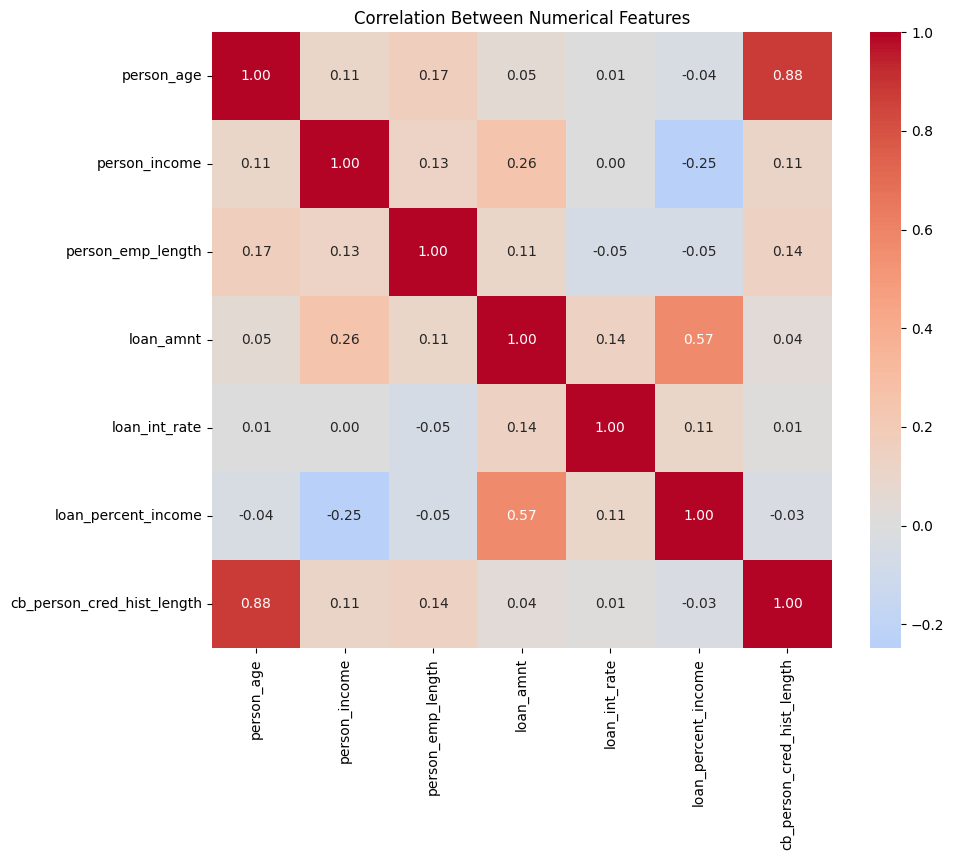

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the numerical features from the training data.
numerical_features = X_train.select_dtypes(include="number")

# Calculate correlations between the numerical features.
correlation_matrix = numerical_features.corr()

# Display the correlation heatmap.
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.show()

 <u>What We Learned from the above result</u>

The correlation heatmap shows that most numerical features have relatively weak relationships with one another. The strongest relationship is between `person_age` and `cb_person_cred_hist_length` (0.88), suggesting that these variables contain some overlapping information. There is also a moderate positive relationship between `loan_amnt` and `loan_percent_income` (0.57). We will consider these relationships when creating new features so that we do not introduce unnecessary redundancy.

## Creating New Features

We will create a small set of candidate features using different approaches: binning, a ratio, and interaction terms. Each feature is chosen to represent a different aspect of a borrower's financial or credit situation. We will then inspect the resulting features for redundancy before deciding which ones to retain.

Creating Income Bands

We will divide `person_income` into four income groups: Low, Lower-Middle, Upper-Middle, and High. The cut-off points will be calculated from the training data only and then applied to both the training and test sets. This prevents information from the test set from influencing how the feature is constructed and allows us to examine whether borrowers at different income levels show different default patterns.

In [30]:
# Get the quartile cut-off points from the training data only.
income_quantiles = X_train["person_income"].quantile([0.25, 0.50, 0.75])

income_bins = [
    -np.inf,
    income_quantiles[0.25],
    income_quantiles[0.50],
    income_quantiles[0.75],
    np.inf
]

income_labels = [
    "Low",
    "Lower-Middle",
    "Upper-Middle",
    "High"
]

# Create the income band for the training data.
X_train["income_band"] = pd.cut(
    X_train["person_income"],
    bins=income_bins,
    labels=income_labels,
    include_lowest=True
)

# Apply the same training cut-offs to the test data.
X_test["income_band"] = pd.cut(
    X_test["person_income"],
    bins=income_bins,
    labels=income_labels,
    include_lowest=True
)

# Check the number of observations in each band.
print("Training data:")
print(X_train["income_band"].value_counts().sort_index())

print("\nTest data:")
print(X_test["income_band"].value_counts().sort_index())

Training data:
income_band
Low             6500
Lower-Middle    6578
Upper-Middle    6371
High            6483
Name: count, dtype: int64

Test data:
income_band
Low             1577
Lower-Middle    1637
Upper-Middle    1552
High            1718
Name: count, dtype: int64


The `income_band` feature groups borrowers into different income levels, but creating the groups alone does not tell us whether they are useful for understanding credit risk. We will therefore compare the default rate across each income band using the training data. This allows us to determine whether borrowers in different income groups show meaningfully different levels of default risk and whether `income_band` captures a useful pattern for the analysis.

In [31]:
# Combine the income band with the corresponding target values.
income_band_analysis = X_train[["income_band"]].copy()
income_band_analysis["loan_status"] = y_train.values

# Calculate the number of loans, defaults, and default rate for each income band.
income_band_default_rate = (
    income_band_analysis
    .groupby("income_band", observed=False)["loan_status"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "loan_count",
        "sum": "default_count",
        "mean": "default_rate"
    })
)

# Convert the default rate to a percentage.
income_band_default_rate["default_rate"] = (
    income_band_default_rate["default_rate"] * 100
)

income_band_default_rate

,loan_count,default_count,default_rate
income_band,,,
Low,6500,2574,39.600000
Lower-Middle,6578,1411,21.450289
Upper-Middle,6371,1076,16.889028
High,6483,610,9.409224


<u>What We Learned from the above result</u>

The income-band analysis shows clear differences in default rates across the four income groups. The Low-income group has the highest default rate at 39.60%, while the High-income group has the lowest at 9.41%. The default rate decreases consistently as income increases, suggesting that `income_band` captures meaningful differences in credit risk. We will therefore retain this engineered feature.

## Creating Additional Numerical Candidate Features

We will test several numerical features that describe a borrower's credit history, employment experience, age, loan burden, and interest burden from different perspectives. These features are being created as candidates to determine whether they provide information that is meaningfully different from the existing variables. We will evaluate their relationships with the existing numerical features before deciding which ones to retain.

In [32]:
# Create additional candidate features using numerical variables only.

# 1. Credit history relative to age.
X_train["credit_history_age_ratio"] = (
    X_train["cb_person_cred_hist_length"] / X_train["person_age"]
)

X_test["credit_history_age_ratio"] = (
    X_test["cb_person_cred_hist_length"] / X_test["person_age"]
)


# 2. Employment length relative to age.
X_train["employment_age_ratio"] = (
    X_train["person_emp_length"] / X_train["person_age"]
)

X_test["employment_age_ratio"] = (
    X_test["person_emp_length"] / X_test["person_age"]
)


# 3. Loan burden combined with interest rate.
X_train["interest_burden"] = (
    X_train["loan_percent_income"] * X_train["loan_int_rate"]
)

X_test["interest_burden"] = (
    X_test["loan_percent_income"] * X_test["loan_int_rate"]
)


# 4. Difference between age and credit-history length.
X_train["age_credit_history_gap"] = (
    X_train["person_age"] - X_train["cb_person_cred_hist_length"]
)

X_test["age_credit_history_gap"] = (
    X_test["person_age"] - X_test["cb_person_cred_hist_length"]
)


# 5. Employment length relative to credit-history length.
X_train["employment_credit_history_ratio"] = (
    X_train["person_emp_length"] /
    X_train["cb_person_cred_hist_length"]
)

X_test["employment_credit_history_ratio"] = (
    X_test["person_emp_length"] /
    X_test["cb_person_cred_hist_length"]
)


# Display the candidate features.
candidate_features = [
    "credit_history_age_ratio",
    "employment_age_ratio",
    "interest_burden",
    "age_credit_history_gap",
    "employment_credit_history_ratio"
]

X_train[candidate_features].head()

,credit_history_age_ratio,employment_age_ratio,interest_burden,age_credit_history_gap,employment_credit_history_ratio
7173,0.086957,0.000000,0.5886,21.0,0.00
16396,0.160000,0.360000,5.0920,21.0,2.25
21744,0.290323,0.000000,0.7194,22.0,0.00
27805,0.222222,0.444444,0.2142,21.0,2.00
24563,0.310345,0.000000,2.8424,20.0,0.00


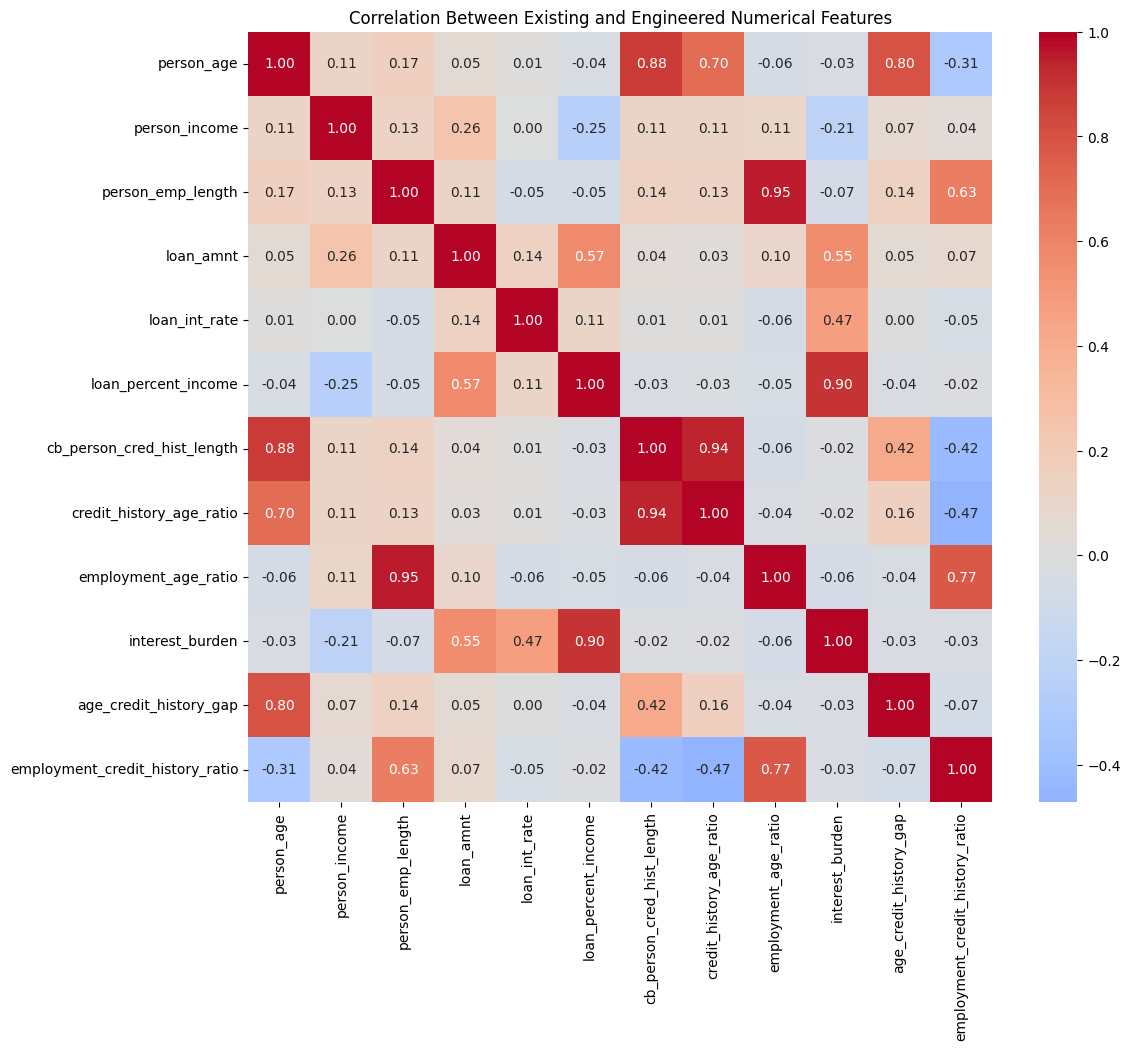

In [33]:
# Check how the candidate features relate to the existing numerical features.

candidate_correlation = X_train.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    candidate_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Existing and Engineered Numerical Features")
plt.show()

## Removing Redundant Candidate Features

The correlation check showed that several of the newly created numerical features were strongly related to existing variables and did not add enough distinct information. We will remove these five candidates and retain `income_band`, which showed clear differences in default rates across income groups.

In [34]:
# Remove the five candidate features we decided not to retain.

candidate_features_to_drop = [
    "credit_history_age_ratio",
    "employment_age_ratio",
    "interest_burden",
    "age_credit_history_gap",
    "employment_credit_history_ratio"
]

X_train = X_train.drop(columns=candidate_features_to_drop)
X_test = X_test.drop(columns=candidate_features_to_drop)

# Check the remaining columns.
print("X_train columns:")
print(X_train.columns.tolist())

print("\nX_test columns:")
print(X_test.columns.tolist())

X_train columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'income_band']

X_test columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'income_band']


Each dropped feature above was highly correlated with an existing one: employment_age_ratio (0.95 with person_emp_length), credit_history_age_ratio (0.94 with cb_person_cred_hist_length), interest_burden (0.90 with loan_percent_income), age_credit_history_gap (0.80 with person_age), and employment_credit_history_ratio (0.77 with employment_age_ratio). They add little new information.

## Creating Interaction Features

We will create two interaction features that combine `loan_percent_income` with specific borrower characteristics. `prior_default_burden` captures loan burden among borrowers with a previous default recorded, while `renter_burden` captures loan burden specifically among borrowers who rent. These features allow us to examine whether loan burden behaves differently for these groups.

In [35]:
# Create the two new interaction features

X_train["prior_default_burden"] = (
    X_train["loan_percent_income"] *
    (X_train["cb_person_default_on_file"] == "Y").astype(int)
)

X_test["prior_default_burden"] = (
    X_test["loan_percent_income"] *
    (X_test["cb_person_default_on_file"] == "Y").astype(int)
)

X_train["renter_burden"] = (
    X_train["loan_percent_income"] *
    (X_train["person_home_ownership"] == "RENT").astype(int)
)

X_test["renter_burden"] = (
    X_test["loan_percent_income"] *
    (X_test["person_home_ownership"] == "RENT").astype(int)
)

# Check the new features.
print("New interaction features:")
print(
    X_train[
        ["prior_default_burden", "renter_burden"]
    ].head()
)

New interaction features:
       prior_default_burden  renter_burden
7173                    0.0           0.09
16396                   0.4           0.40
21744                   0.0           0.11
27805                   0.0           0.00
24563                   0.0           0.19


prior_default_burden above reflects that a heavy loan is riskier for someone who has defaulted before. renter_burden above reflects that renters have no home asset behind the loan, so a heavy loan burden is riskier for them.

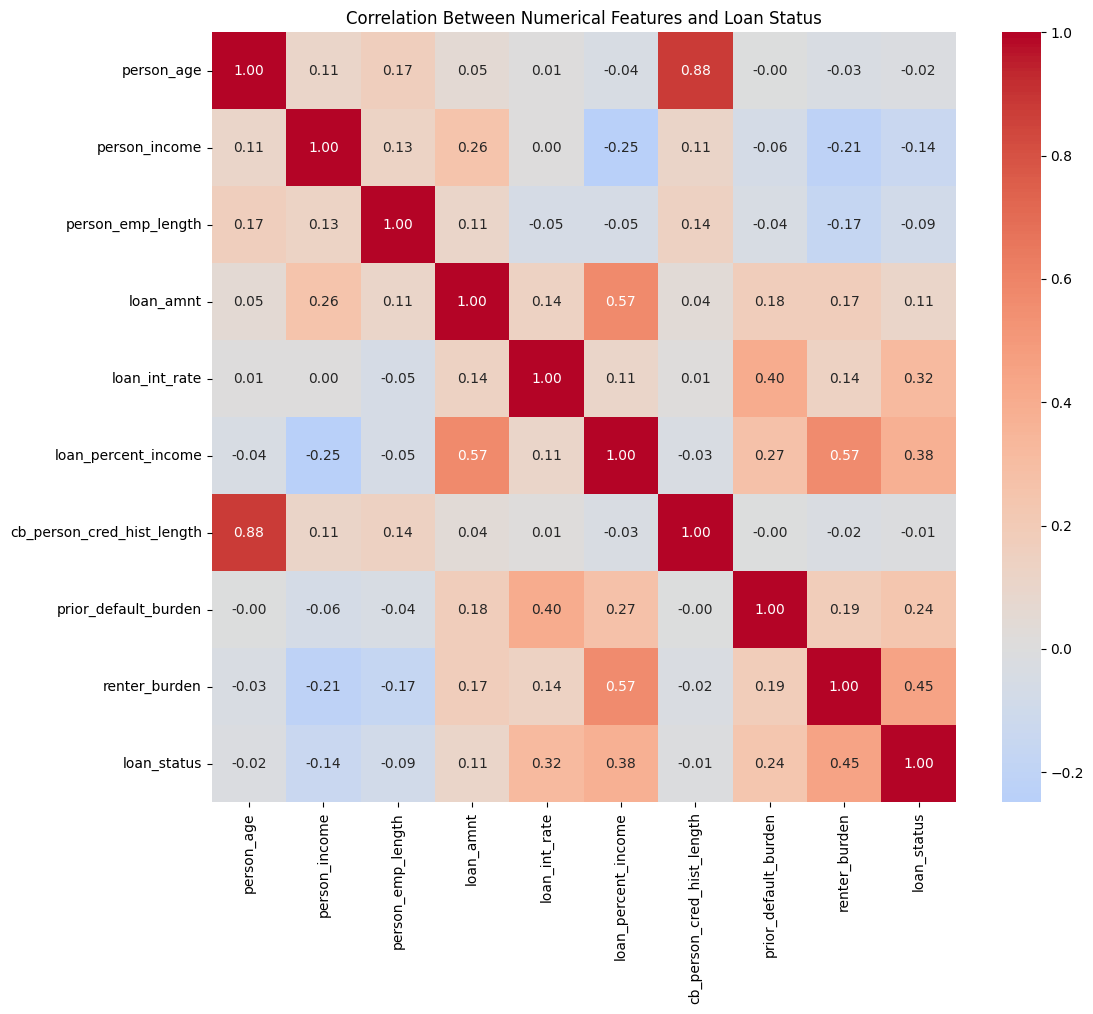

In [36]:
# Check correlations among numerical features and the new interaction features.

correlation_data = X_train.select_dtypes(include="number").copy()
correlation_data["loan_status"] = y_train

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Features and Loan Status")
plt.show()

 <u>What We Learned from the above result</u>

The correlation analysis shows that the original numerical features generally have weak to moderate relationships with `loan_status`. For example, `loan_amnt` has a correlation of 0.11, while `person_income` has a weak negative correlation of -0.14. These values do not mean that the features are unimportant, since a feature can still provide useful information when combined with other variables or captured through nonlinear relationships. The engineered interaction features show stronger relationships with the target, particularly `renter_burden` (0.45). Therefore, we will retain the original features and the three engineered features and allow the classification models to determine their overall predictive usefulness.

## Encoding Categorical Features

The categorical variables will be encoded according to their meaning. `loan_grade` and `income_band` have a meaningful order, so their ordering will be preserved using ordinal encoding. `cb_person_default_on_file` has two possible states, so it will be represented as 0 and 1. `person_home_ownership` and `loan_intent` have no natural order, so one-hot encoding will be used for these variables.

In [37]:
# Ordinal encoding for features with a meaningful order.

loan_grade_mapping = {
    "A": 1,
    "B": 2,
    "C": 3,
    "D": 4,
    "E": 5,
    "F": 6,
    "G": 7
}

income_band_mapping = {
    "Low": 1,
    "Lower-Middle": 2,
    "Upper-Middle": 3,
    "High": 4
}

X_train["loan_grade"] = X_train["loan_grade"].map(loan_grade_mapping)
X_test["loan_grade"] = X_test["loan_grade"].map(loan_grade_mapping)

X_train["income_band"] = X_train["income_band"].map(income_band_mapping)
X_test["income_band"] = X_test["income_band"].map(income_band_mapping)

# Binary encoding for previous default status.

default_mapping = {
    "N": 0,
    "Y": 1
}

X_train["cb_person_default_on_file"] = (
    X_train["cb_person_default_on_file"].map(default_mapping)
)

X_test["cb_person_default_on_file"] = (
    X_test["cb_person_default_on_file"].map(default_mapping)
)

# One-hot encoding for nominal categorical features.

X_train = pd.get_dummies(
    X_train,
    columns=["person_home_ownership", "loan_intent"],
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["person_home_ownership", "loan_intent"],
    drop_first=True,
    dtype=int
)

# Make sure train and test have exactly the same columns.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nRemaining data types:")
print(X_train.dtypes)

X_train shape: (25932, 20)
X_test shape: (6484, 20)

Remaining data types:
person_age                      float64
person_income                     int64
person_emp_length               float64
loan_grade                        int64
loan_amnt                         int64
loan_int_rate                   float64
loan_percent_income             float64
cb_person_default_on_file         int64
cb_person_cred_hist_length        int64
income_band                    category
prior_default_burden            float64
renter_burden                   float64
person_home_ownership_OTHER       int64
person_home_ownership_OWN         int64
person_home_ownership_RENT        int64
loan_intent_EDUCATION             int64
loan_intent_HOMEIMPROVEMENT       int64
loan_intent_MEDICAL               int64
loan_intent_PERSONAL              int64
loan_intent_VENTURE               int64
dtype: object


For the one-hot encoded variables above, `drop_first=True` was used to remove one category from each group. The omitted category serves as the reference category, which avoids creating redundant dummy variables while still representing the information in the original categorical feature.

In [38]:
# Convert the ordered income bands to a numeric data type.
X_train["income_band"] = X_train["income_band"].astype(int)
X_test["income_band"] = X_test["income_band"].astype(int)

print("income_band dtype in X_train:", X_train["income_band"].dtype)
print("income_band dtype in X_test:", X_test["income_band"].dtype)

income_band dtype in X_train: int64
income_band dtype in X_test: int64


From the above, the ordered `income_band` categories have already been mapped according to their natural order. We converted the resulting values to an integer data type so that the feature can be treated as a numerical variable during subsequent scaling and modelling.

## Scaling the Features

We will use `StandardScaler` because the numerical features have very different ranges. Standardization places the features on a comparable scale, with values centered around zero and measured in terms of standard deviations. This is particularly important for K-Means because it uses distances to form clusters; without scaling, variables with larger numerical values could have a greater influence on the clustering results. The scaler will be fitted on the training data only and then applied to the test data.

In [39]:
from sklearn.preprocessing import StandardScaler

# Create the scaler.
scaler = StandardScaler()

# Fit on the training data and transform both datasets.
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert the scaled arrays back to DataFrames.
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Check the results.
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nFirst five rows of the scaled training data:")
print(X_train_scaled.head())

X_train_scaled shape: (25932, 20)
X_test_scaled shape: (6484, 20)

First five rows of the scaled training data:
       person_age  person_income  person_emp_length  loan_grade  loan_amnt  \
7173    -0.761590       0.158047          -1.196858   -1.045852  -0.412319   
16396   -0.437859      -0.061331           1.076298    0.671430   2.450820   
21744    0.533335      -0.201936          -1.196858   -1.045852  -0.571382   
27805   -0.114127       2.570406           1.834017   -1.045852  -0.571382   
24563    0.209604      -0.187481          -1.196858    1.530071   0.064871   

       loan_int_rate  loan_percent_income  cb_person_default_on_file  \
7173       -1.456649            -0.756336                  -0.463203   
16396       0.556474             2.147007                   2.158882   
21744      -1.456649            -0.569023                  -0.463203   
27805      -1.261516            -1.318273                  -0.463203   
24563       1.281719             0.180226                  

# Part 3. Clustering Analysis

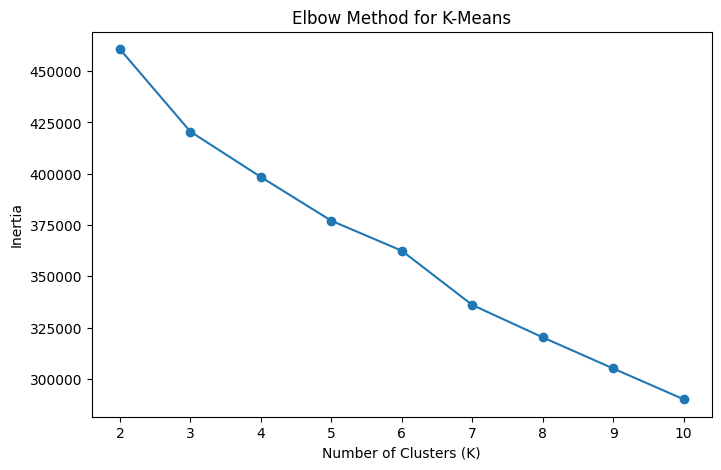

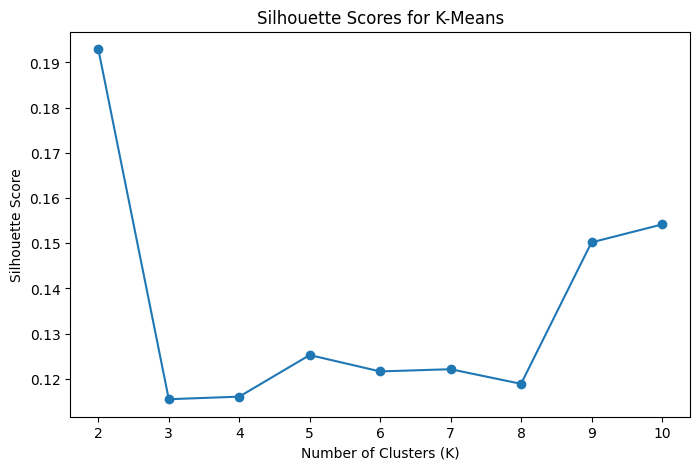

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Test K values from 2 to 10.
k_values = range(2, 11)

inertia_scores = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_train_scaled)

    inertia_scores.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_train_scaled, cluster_labels)
    )

# Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.show()

# Silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for K-Means")
plt.xticks(list(k_values))
plt.show()

In [41]:
# Compare inertia and silhouette scores for each K.

kmeans_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_scores,
    "Silhouette_Score": silhouette_scores
})

kmeans_results

,K,Inertia,Silhouette_Score
0,2,460691.768255,0.192918
1,3,420519.200512,0.115500
2,4,398412.583649,0.116072
3,5,377096.412834,0.125269
4,6,362470.816606,0.121648
5,7,336054.797730,0.122141
6,8,320266.691017,0.118905
7,9,305088.899365,0.150194
8,10,290102.750119,0.154153


## Selecting the Final Number of Clusters

The elbow curve shows that inertia decreases substantially as the number of clusters increases, with the largest reduction occurring from K=2 to K=3. After this point, the reductions become more gradual and there is no sharply defined elbow. The silhouette scores provide a clearer signal, with K=2 producing the highest score of 0.193 among all tested values. The elbow curve has no clear bend, so the choice rests mainly on silhouette. K=2 scores 0.193 and every other K scores between about 0.12 and 0.15. Even so, 0.19 is low, so the clusters are only weakly separated and should be read as broad segments.

In [42]:
# Fit the final K-Means model using the selected K.
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign each training observation to a cluster.
train_clusters = final_kmeans.fit_predict(X_train_scaled)

# Add the cluster labels to a separate DataFrame for analysis.
clustered_train = X_train.copy()
clustered_train["cluster"] = train_clusters

# Check the number of observations in each cluster.
print("Number of observations in each cluster:")
print(clustered_train["cluster"].value_counts().sort_index())

Number of observations in each cluster:
cluster
0     4891
1    21041
Name: count, dtype: int64


In [43]:
# Compare the average values of the numerical features across the clusters.

cluster_profile = (
    clustered_train
    .groupby("cluster")
    .mean(numeric_only=True)
    .T
)

cluster_profile

cluster,0,1
person_age,27.861174,27.668790
person_income,65563.536087,65890.105841
person_emp_length,4.419137,4.812937
loan_grade,3.682887,1.877525
loan_amnt,10454.687181,9391.675776
loan_int_rate,14.421605,10.227988
loan_percent_income,0.183292,0.167843
cb_person_default_on_file,0.936618,0.000000
cb_person_cred_hist_length,5.861174,5.783518
income_band,2.451237,2.505204


 <u>What We Learned from the above result</u>

The two clusters show clear differences in their credit-related characteristics. Cluster 0 has a higher average loan grade, higher interest rate, higher loan-to-income percentage, and a much higher proportion of borrowers with a previous default recorded. In contrast, Cluster 1 has lower loan grades, lower interest rates, and no recorded previous defaults. The two clusters have similar average ages and incomes, suggesting that the clustering is driven more by credit history and loan characteristics than by age or income. Based on these characteristics, we name Cluster 0 (4,891 borrowers) the "high-burden, prior-default borrowers" and Cluster 1 (21,041 borrowers) the "clean-record, lower-rate borrowers". We compare their actual default rates in Part 6.

In [44]:
from sklearn.decomposition import PCA

# Reduce the scaled training data to two principal components.
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

# Create a DataFrame for the PCA results.
pca_data = pd.DataFrame(
    X_train_pca,
    columns=["PC1", "PC2"],
    index=X_train.index
)

# Add the K-Means cluster labels.
pca_data["cluster"] = train_clusters

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance explained by the two components:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.15765918 0.122546  ]

Total variance explained by the two components:
0.28020517834352787


 <u>What We Learned from the above result</u>

The first two principal components explain approximately 28.02% of the total variation in the data. This means that the two-dimensional PCA representation does not capture all of the information contained in the original features. However, it provides a useful two-dimensional view of the K-Means clusters, which is required for the clustering analysis.

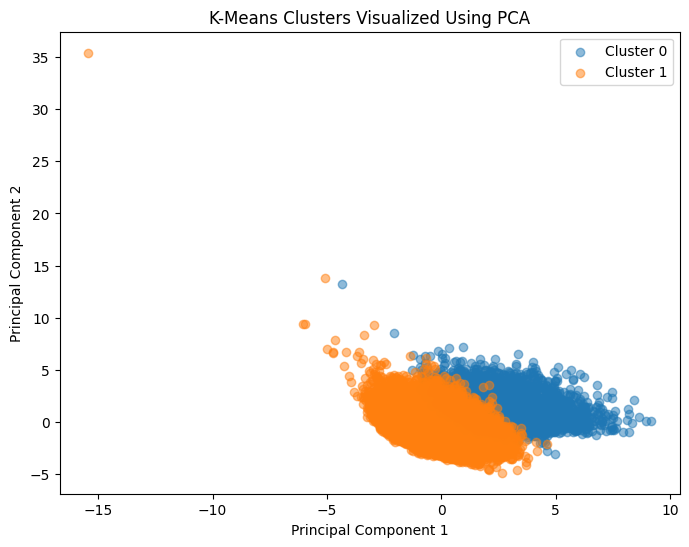

In [45]:
# Visualize the two K-Means clusters using the first two PCA components.

plt.figure(figsize=(8, 6))

for cluster in sorted(pca_data["cluster"].unique()):
    cluster_data = pca_data[pca_data["cluster"] == cluster]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.5
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized Using PCA")
plt.legend()
plt.show()

 <u>What We Learned from the above result</u>

The PCA plot shows that Cluster 0 and Cluster 1 are mostly found in different areas, but there is still a lot of overlap between them. Since the first two principal components explain only about 28.02% of the variation in the data, the plot does not show everything the clusters are based on. It is therefore useful for visualizing the clusters, but we should rely on the other clustering results as well when interpreting them.

# Part 4. Classification


<u> Why These Classification Models?</U>

We selected Logistic Regression, Decision Tree, and Random Forest because they provide three different approaches to the classification problem rather than relying on models that learn in similar ways.

- Logistic Regression

Logistic Regression will provide a simple and interpretable baseline for predicting loan default. It estimates the probability that a borrower belongs to the default class based on the available features. This gives us a useful reference point for understanding how well a relatively straightforward linear classification approach performs on the dataset.

 - Decision Tree

Decision Tree is included because the relationship between borrower characteristics and loan default may not be purely linear. A decision tree can create rules based on different features and can also capture interactions between variables. This allows us to examine whether a rule-based, nonlinear approach can identify patterns that Logistic Regression may not capture.

 - Random Forest

Random Forest is included as an ensemble approach based on multiple decision trees. Instead of relying on one tree, it combines the predictions of many trees, allowing the model to capture more complex patterns while reducing the dependence on any single tree. Comparing it with a single Decision Tree also allows us to see whether combining multiple trees improves the classification results.

Together, these models give us a comparison between a linear model, a single nonlinear tree-based model, and an ensemble tree-based model. The models will be compared using the same evaluation metrics, and their performance on the test set will determine which approach is most suitable for the later stages of the analysis.

 A stratified Dummy Classifier is also included as a benchmark to check whether the trained models provide meaningful improvement over a simple prediction strategy.

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Create the models.
dummy_model = DummyClassifier(
    strategy="stratified",
    random_state=42
)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

random_forest_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

models = {
    "Dummy Classifier": dummy_model,
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

print("Models created successfully.")

Models created successfully.


## Training the Classification Models


In [47]:
# Train the models
dummy_model.fit(X_train, y_train)

logistic_model.fit(X_train_scaled, y_train)

decision_tree_model.fit(X_train, y_train)

random_forest_model.fit(X_train, y_train)

print("All models trained successfully.")

All models trained successfully.


In [48]:
# Store predictions and probabilities
predictions = {}
probabilities = {}

# Dummy Classifier
predictions["Dummy Classifier"] = dummy_model.predict(X_test)
probabilities["Dummy Classifier"] = dummy_model.predict_proba(X_test)[:, 1]

# Logistic Regression
predictions["Logistic Regression"] = logistic_model.predict(X_test_scaled)
probabilities["Logistic Regression"] = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Decision Tree
predictions["Decision Tree"] = decision_tree_model.predict(X_test)
probabilities["Decision Tree"] = decision_tree_model.predict_proba(X_test)[:, 1]

# Random Forest
predictions["Random Forest"] = random_forest_model.predict(X_test)
probabilities["Random Forest"] = random_forest_model.predict_proba(X_test)[:, 1]


# Calculate evaluation metrics
results = []

for model_name in models:
    y_pred = predictions[model_name]
    y_prob = probabilities[model_name]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

# Create comparison table
results_df = pd.DataFrame(results)

print("Model Comparison:")
display(results_df.round(4))


# Display confusion matrices
for model_name in models:
    print(f"\n{model_name}")
    print(confusion_matrix(y_test, predictions[model_name]))

Model Comparison:


,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Dummy Classifier,0.6542,0.2070,0.2052,0.2061,0.4926
1,Logistic Regression,0.8658,0.7745,0.5451,0.6399,0.8690
2,Decision Tree,0.8860,0.7271,0.7666,0.7463,0.8430
3,Random Forest,0.9343,0.9679,0.7236,0.8281,0.9284



Dummy Classifier
[[3951 1115]
 [1127  291]]

Logistic Regression
[[4841  225]
 [ 645  773]]

Decision Tree
[[4658  408]
 [ 331 1087]]

Random Forest
[[5032   34]
 [ 392 1026]]


<u>What We Learned from the above result</u>

The three classification models perform substantially better than the Dummy Classifier, showing that the features contain useful information for predicting loan default. Logistic Regression has the lowest F1 score among the three models, while Decision Tree achieves higher recall and F1. Random Forest records the highest accuracy, precision, F1, and ROC AUC in the baseline comparison, although its recall is slightly lower than the Decision Tree. These results give us a useful baseline for Part 5, where we will investigate whether class weights, threshold tuning, and SMOTE can improve the models' ability to identify default cases.

<u> Understanding the Confusion Matrix Above</u>

The confusion matrix shows how the model's predictions compare with the actual loan status. The rows represent the actual classes and the columns represent the predicted classes. For our problem, `0` means no default and `1` means default.

The four values represent:
- **Top-left:** correctly predicted no-default cases (True Negatives)
- **Top-right:** no-default cases incorrectly predicted as defaults (False Positives)
- **Bottom-left:** actual defaults incorrectly predicted as no defaults (False Negatives)
- **Bottom-right:** correctly predicted defaults (True Positives)

The False Negatives are particularly important in this problem because they represent borrowers who actually defaulted but were not identified by the model

# Part 5. Imbalance Handling

The target variable is imbalanced, with default cases representing a smaller proportion of the observations. This can make a model less sensitive to the positive class. We will therefore test two approaches for handling the imbalance: class weighting and threshold tuning. The results will be compared with the baseline models from Part 4 to determine whether these approaches improve the identification of default cases.

## Applying Class Weights

The default class represents a smaller proportion of the data, so we will use class weighting to give greater importance to default cases during model training. This allows the models to place more emphasis on correctly identifying the minority class without creating new observations. We will compare the weighted models with their baseline versions using the same evaluation metrics.

In [49]:
# Create class-weighted models
logistic_weighted = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

decision_tree_weighted = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

random_forest_weighted = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

weighted_models = {
    "Logistic Regression": logistic_weighted,
    "Decision Tree": decision_tree_weighted,
    "Random Forest": random_forest_weighted
}

# Train the class-weighted models
logistic_weighted.fit(X_train_scaled, y_train)
decision_tree_weighted.fit(X_train, y_train)
random_forest_weighted.fit(X_train, y_train)

print("Class-weighted models trained successfully.")

Class-weighted models trained successfully.


The class-weighted models will be evaluated using the same metrics used for the baseline models: accuracy, precision, recall, F1, and ROC AUC. Their confusion matrices will also be examined. This allows us to determine whether giving greater importance to default cases actually improves the models' ability to identify defaults and whether any improvement comes with a trade-off in precision or overall accuracy.

In [50]:
# Store class-weighted predictions and probabilities
weighted_predictions = {}
weighted_probabilities = {}

# Logistic Regression
weighted_predictions["Logistic Regression"] = logistic_weighted.predict(X_test_scaled)
weighted_probabilities["Logistic Regression"] = (
    logistic_weighted.predict_proba(X_test_scaled)[:, 1]
)

# Decision Tree
weighted_predictions["Decision Tree"] = decision_tree_weighted.predict(X_test)
weighted_probabilities["Decision Tree"] = (
    decision_tree_weighted.predict_proba(X_test)[:, 1]
)

# Random Forest
weighted_predictions["Random Forest"] = random_forest_weighted.predict(X_test)
weighted_probabilities["Random Forest"] = (
    random_forest_weighted.predict_proba(X_test)[:, 1]
)


# Calculate evaluation metrics
weighted_results = []

for model_name in weighted_models:
    y_pred = weighted_predictions[model_name]
    y_prob = weighted_probabilities[model_name]

    weighted_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

# Create comparison table
weighted_results_df = pd.DataFrame(weighted_results)

print("Class-Weighted Model Comparison:")
display(weighted_results_df.round(4))


# Display confusion matrices
for model_name in weighted_models:
    print(f"\n{model_name} - Class Weighted")
    print(confusion_matrix(y_test, weighted_predictions[model_name]))

Class-Weighted Model Comparison:


,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.8004,0.5300,0.7729,0.6288,0.8704
1,Decision Tree,0.8973,0.7652,0.7652,0.7652,0.8497
2,Random Forest,0.9334,0.9740,0.7144,0.8242,0.9295



Logistic Regression - Class Weighted
[[4094  972]
 [ 322 1096]]

Decision Tree - Class Weighted
[[4733  333]
 [ 333 1085]]

Random Forest - Class Weighted
[[5039   27]
 [ 405 1013]]


<u>What We Learned from the above result</u>

Class weighting affected the three models differently. Logistic Regression showed a large increase in recall from 0.5451 to 0.7729, meaning it identified more of the actual default cases, but its precision decreased from 0.7745 to 0.5300 and its F1 score also decreased. Decision Tree had a small improvement in F1 from 0.7463 to 0.7652, while its recall changed only slightly. Random Forest also showed a small decrease in F1 from 0.8281 to 0.8242, although its ROC AUC remained high at 0.9295. These results show that class weighting can improve the identification of default cases, but the improvement may come with a trade-off in precision. We will therefore test threshold tuning as a second approach to managing the class imbalance.

## Threshold Tuning

A classification model normally uses a probability threshold of 0.50 to convert predicted probabilities into class predictions. However, changing this threshold changes the balance between precision and recall.

For loan default prediction, we assume that missing an actual defaulter (false negative) is more costly than incorrectly flagging a borrower who would not default (false positive). For this analysis, we assign a cost of 3 to a false negative and a cost of 1 to a false positive.

We will use a validation portion of the training data to examine different thresholds using the precision-recall curve and select the threshold that minimizes the assumed business cost. The test set will remain untouched until the final evaluation.

In [51]:
from sklearn.model_selection import train_test_split

X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model-training data:", X_train_model.shape)
print("Validation data:", X_val.shape)

Model-training data: (20745, 20)
Validation data: (5187, 20)


### Why Random Forest Was Selected for Threshold Tuning

Random Forest was selected for threshold tuning because it produced the highest F1 score and ROC AUC among the class-weighted classification models evaluated earlier. F1 provides a balance between precision and recall, while ROC AUC measures the model's ability to distinguish between default and non-default cases across probability thresholds. Although Logistic Regression and Decision Tree achieved higher recall than Random Forest, Random Forest provided the strongest overall balance based on F1 and ROC AUC. We therefore use the class-weighted Random Forest to investigate whether adjusting its probability threshold can improve its operating performance under a stated business cost.

In [52]:
threshold_rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

threshold_rf.fit(X_train_model, y_train_model)

val_probabilities = threshold_rf.predict_proba(X_val)[:, 1]

print("Validation probabilities generated successfully.")

Validation probabilities generated successfully.


In [53]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

print(f"Number of thresholds examined: {len(thresholds)}")

Number of thresholds examined: 100


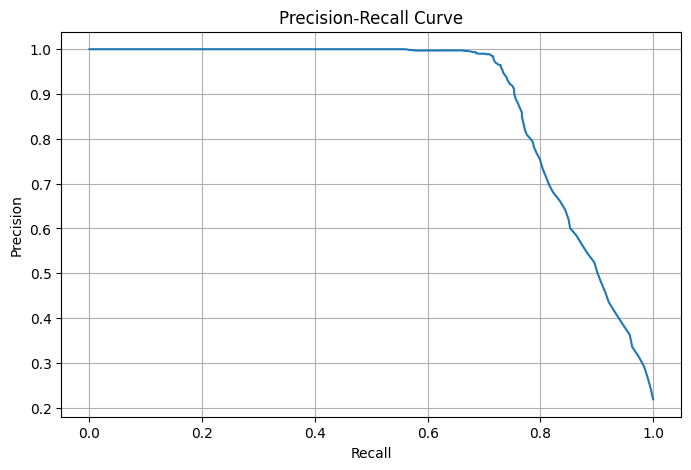

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid()
plt.show()

## Selecting a Threshold Using Business Cost

To select an operating threshold, we will compare the business cost associated with each threshold examined above. We assume that a false negative, where an actual defaulter is predicted as a non-defaulter, has a cost three times that of a false positive. Therefore, we assign a cost of 3 to each false negative and a cost of 1 to each false positive. We assume a missed default costs about three times a false alarm, because a default loses the unpaid loan, while a rejected good borrower only costs the lender interest income.


The threshold with the lowest total business cost on the validation data will be selected for the final evaluation.

In [55]:
false_negative_cost = 3
false_positive_cost = 1

threshold_results = []

for i, threshold in enumerate(thresholds):
    val_predictions = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        val_predictions
    ).ravel()

    total_cost = (
        false_negative_cost * fn
        + false_positive_cost * fp
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision[i],
        "Recall": recall[i],
        "False Positives": fp,
        "False Negatives": fn,
        "Business Cost": total_cost
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df
    .sort_values("Business Cost")
    .head(10)
)

,Threshold,Precision,Recall,False Positives,False Negatives,Business Cost
39,0.39,0.911419,0.753086,83,280,923
40,0.40,0.918015,0.750441,76,283,925
36,0.36,0.879592,0.760141,118,272,934
38,0.38,0.898109,0.753968,97,279,934
35,0.35,0.871098,0.762787,128,269,935
41,0.41,0.922574,0.746032,71,288,935
34,0.34,0.858835,0.767196,143,264,935
37,0.37,0.888199,0.756614,108,276,936
42,0.42,0.925439,0.744268,68,290,938
43,0.43,0.931340,0.741623,62,293,941


With a 3:1 cost, theory would point to a threshold near 0.25. But Random Forest probabilities are not well calibrated, and class weighting already pushes them upward. So we relied on the validation cost table, where 0.39 had the lowest cost (923), with 0.40 close behind (925).

## Evaluating the Selected Threshold on the Test Set

The threshold with the lowest business cost on the validation data will be used as the operating threshold. We will now retrain the class-weighted Random Forest on the full training data, apply the selected threshold to the untouched test data, and evaluate its performance. The test set is used only at this stage for the final evaluation of the threshold-tuned model.

In [56]:
# Select the threshold with the lowest business cost
selected_threshold = threshold_results_df.loc[
    threshold_results_df["Business Cost"].idxmin(),
    "Threshold"
]

print(f"Selected threshold: {selected_threshold:.2f}")

# Retrain the class-weighted Random Forest on the full training data
final_weighted_rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_weighted_rf.fit(X_train, y_train)

# Generate default probabilities for the untouched test set
test_probabilities = final_weighted_rf.predict_proba(X_test)[:, 1]

# Apply the selected threshold
test_predictions_threshold = (
    test_probabilities >= selected_threshold
).astype(int)

print("Threshold-tuned test predictions generated successfully.")

Selected threshold: 0.39
Threshold-tuned test predictions generated successfully.


## Evaluating the Threshold-Tuned Model

The selected threshold of 0.39 will now be evaluated on the untouched test set. We will compare its performance with the baseline Random Forest and the class-weighted Random Forest using the same classification metrics.

In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

threshold_tuned_results = {
    "Model": "Random Forest - Threshold Tuned",
    "Accuracy": accuracy_score(y_test, test_predictions_threshold),
    "Precision": precision_score(y_test, test_predictions_threshold),
    "Recall": recall_score(y_test, test_predictions_threshold),
    "F1": f1_score(y_test, test_predictions_threshold),
    "ROC AUC": roc_auc_score(y_test, test_probabilities)
}

threshold_tuned_results_df = pd.DataFrame([threshold_tuned_results])

display(threshold_tuned_results_df.round(4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions_threshold))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Random Forest - Threshold Tuned,0.9277,0.9151,0.7377,0.8169,0.9295


Confusion Matrix:
[[4969   97]
 [ 372 1046]]


<u>What We Learned from the above result</u>

The threshold-tuned Random Forest achieved an accuracy of 92.77%, precision of 91.51%, recall of 73.77%, F1 score of 81.69%, and ROC AUC of 92.95% on the test set. The confusion matrix shows that the model correctly identified 1,046 default cases and missed 372 default cases, while incorrectly classifying 97 non-default cases as defaults.

The threshold of 0.39 was selected using the validation data based on the stated business cost assumption that a false negative is three times as costly as a false positive. The test set was kept separate from this threshold-selection process and was used only for the final evaluation.

The threshold tuning produced a slightly lower F1 score than the class-weighted Random Forest baseline, while maintaining a high ROC AUC. This shows that adjusting the probability threshold can change the balance between precision and recall.

## Comparing Random Forest Approaches

We will now compare the baseline, class-weighted, and threshold-tuned Random Forest models using the same evaluation metrics. This allows us to determine how class weighting and threshold tuning affected model performance and whether either approach improved the baseline model.

In [58]:
rf_comparison = pd.DataFrame([
    results_df[results_df["Model"] == "Random Forest"].iloc[0].to_dict(),
    weighted_results_df[weighted_results_df["Model"] == "Random Forest"].iloc[0].to_dict(),
    threshold_tuned_results
])

rf_comparison.loc[0, "Model"] = "Baseline Random Forest"
rf_comparison.loc[1, "Model"] = "Class-Weighted Random Forest"

display(rf_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Baseline Random Forest,0.9343,0.9679,0.7236,0.8281,0.9284
1,Class-Weighted Random Forest,0.9334,0.9740,0.7144,0.8242,0.9295
2,Random Forest - Threshold Tuned,0.9277,0.9151,0.7377,0.8169,0.9295


 <u>What We Learned from the above result</u>

The comparison shows that class weighting and threshold tuning affected the Random Forest differently. The baseline Random Forest achieved the highest accuracy, precision, and F1 score, with an F1 score of 0.8281. Class weighting lowered recall from 0.7236 to 0.7144 and raised ROC AUC from 0.9284 to 0.9295, but reduced the F1 score to 0.8242. Threshold tuning produced an F1 score of 0.8169 and recall of 0.7377.

The threshold-tuned model was selected using the stated business-cost assumption rather than by maximizing F1. Therefore, its purpose was to find an operating threshold that reduced the assumed cost of false negatives and false positives, rather than simply maximizing a single evaluation metric. Overall, the imbalance-handling techniques changed the balance between precision, recall, and business cost, but neither technique produced a higher test-set F1 score than the baseline Random Forest.

## Comparing Business Cost Across Random Forest Approaches

The threshold was selected using the validation data under the assumption that a false negative has three times the cost of a false positive. We will now calculate the same business cost for the baseline, class-weighted, and threshold-tuned Random Forest models on the test set. This allows us to see how the approaches compare on the unseen test data.

In [59]:
false_negative_cost = 3
false_positive_cost = 1

rf_business_costs = []

rf_test_predictions = {
    "Random Forest": predictions["Random Forest"],
    "Random Forest - Class Weighted": weighted_predictions["Random Forest"],
    "Random Forest - Threshold Tuned": test_predictions_threshold
}

for model_name, y_pred in rf_test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    business_cost = (
        false_negative_cost * fn
        + false_positive_cost * fp
    )

    rf_business_costs.append({
        "Model": model_name,
        "False Positives": fp,
        "False Negatives": fn,
        "Business Cost": business_cost
    })

rf_business_costs_df = pd.DataFrame(rf_business_costs)

display(rf_business_costs_df)

,Model,False Positives,False Negatives,Business Cost
0,Random Forest,34,392,1210
1,Random Forest - Class Weighted,27,405,1242
2,Random Forest - Threshold Tuned,97,372,1213


 <u>What We Learned from the above result</u>

The test-set business-cost comparison shows that the baseline Random Forest produced the lowest business cost under the stated 3:1 false-negative-to-false-positive cost assumption. The baseline recorded 392 false negatives and 34 false positives, giving a business cost of 1,210. The class-weighted Random Forest increased false negatives to 405 but reduced false positives to 27, resulting in a slightly higher business cost of 1,242. The threshold-tuned Random Forest reduced false negatives from 392 to 372, but raised false positives from 34 to 97, giving a business cost of 1,213. That is only 3 higher than the baseline.
The baseline still wins narrowly.

This shows that reducing false negatives alone does not guarantee a lower business cost.

# Part 6. The Tie-In

The K-Means analysis in Part 3 identified two groups of borrowers based on their characteristics. We will now connect those clusters to the loan default outcome by calculating the positive-class rate within each cluster. This will show whether the groups identified without using the target variable differ in their observed default rates.

In [60]:
cluster_default_rate = pd.DataFrame({
    "cluster": train_clusters,
    "loan_status": y_train
})

cluster_default_rate = (
    cluster_default_rate
    .groupby("cluster")["loan_status"]
    .agg(["mean", "count"])
    .reset_index()
)

cluster_default_rate["Default Rate (%)"] = (
    cluster_default_rate["mean"] * 100
)

cluster_default_rate = cluster_default_rate.drop(
    columns="mean"
)

display(cluster_default_rate.round(2))

,cluster,count,Default Rate (%)
0,0,4891,40.58
1,1,21041,17.52


 <u>What We Learned from the above result</u>

The two K-Means clusters have noticeably different default rates. Cluster 0 has a default rate of 40.58%, while Cluster 1 has a default rate of 17.52%. This shows that the borrower profiles identified by K-Means are associated with different levels of observed default risk in the historical training data.

Cluster 0 therefore represents a borrower profile with a substantially higher historical default rate, while Cluster 1 represents a profile with a lower historical default rate. This suggests that the features used by K-Means contain patterns that are related to loan default, even though `loan_status` was not used when creating the clusters.

However, this result should be interpreted as an association rather than a direct prediction. K-Means grouped borrowers according to similarities in their features, and the default rates were calculated afterward using `y_train` to understand how the discovered clusters relate to the observed outcomes.

# Part 7. Conclusion and Recommendations

**<u>Final Model Selection</u>**

Based on the models and imbalance-handling approaches evaluated in this project, the baseline Random Forest is selected as the final model. It achieved the highest F1 score of 0.8281 and a strong ROC AUC of 0.9284 on the test set. It also recorded the highest precision among the classification models evaluated. Although class weighting lowered recall and slightly raised AUC, while threshold tuning raised recall, neither approach improved the overall F1 score or the test business cost compared with the baseline Random Forest.

The model also performed substantially better than the Dummy Classifier, which had an F1 score of 0.2061 and ROC AUC of 0.4926. Therefore, the baseline Random Forest provides the strongest overall performance among the approaches tested and is selected as the final model for this project.

**<u>What We Would Improve With Another Month</u>**

With another month, we would focus on further improving model reliability and generalisation. This could include more extensive hyperparameter tuning, additional feature engineering based on credit-risk relationships, and cross-validation to obtain a more robust estimate of model performance. We could also investigate additional imbalance-handling methods and compare their effects under different business cost assumptions. Also I would drop the loan_grade feature, assuming the company would not compute the loan grade status of each potential candidates before making decisions on granting the loans. This would allow me to work from another angle.

**<u>K-Means Clustering vs Classification</u>**

The K-Means analysis and classification models provided different types of information. K-Means grouped borrowers according to similarities in their characteristics without using `loan_status`. After clustering, Cluster 0 had a historical default rate of 40.58%, compared with 17.52% for Cluster 1, showing that the discovered borrower profiles were associated with different levels of observed default risk.

However, K-Means does not directly predict whether an individual borrower will default. The classification models use the known historical outcomes to learn the relationship between borrower characteristics and loan status, allowing them to make predictions for new borrowers. Therefore, K-Means provides useful borrower segmentation, while the classification model is more directly suited to individual default prediction.

The clusters showed that borrowers split mainly on credit history (prior default, grade, interest rate) and not on age or income. Even the lower-risk cluster still has 17.5% default, so the segments alone are not enough, and the classifier is needed for individual decisions.

**<u>Hardest Decision in the Project</u>**

The hardest decision was determining how to handle the imbalance in the target variable without assuming that every imbalance-handling technique would improve the model. Class weighting increased recall for some models, particularly Logistic Regression, but it did not improve the F1 score of the Random Forest. Threshold tuning also provided a different trade-off between false positives and false negatives but did not produce a lower test business cost than the baseline Random Forest under the stated cost assumption.

This required comparing the models using multiple metrics rather than selecting a model based on a single measure. The final decision was therefore based on the overall test performance and the business cost results obtained during the analysis.

Another hard decision was whether to keep loan_grade as a predictor, since it may not be available when a loan is approved. We kept it under our timing assumption, and removing it is the first thing we would test next.

# Classification Depth Track

For the Depth Track, we will go deeper into classification by evaluating multiple classifiers with cross-validation, comparing their ROC curves, and examining feature importance across the models.

In [61]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold stratified cross-validation setup complete.")

5-fold stratified cross-validation setup complete.



**<u>Adding Gradient Boosting</u>**

To meet the requirement of evaluating four or more classifiers in the Depth Track, we will add Gradient Boosting to the three classifiers used earlier: Logistic Regression, Decision Tree, and Random Forest. Gradient Boosting is another ensemble method that builds trees sequentially, with each new tree learning from the errors of the previous trees. This gives us a fourth classification approach to compare during cross-validation.

In [62]:
from sklearn.ensemble import GradientBoostingClassifier

depth_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Four classification models are ready for cross-validation.")

Four classification models are ready for cross-validation.


For cross-validation, Logistic Regression will use StandardScaler within a pipeline so that scaling is fitted separately within each training fold. Decision Tree, Random Forest, and Gradient Boosting do not require feature scaling, so they will use the training features without scaling. This keeps the preprocessing appropriate for each model and prevents information from one validation fold from being used during training.

In [63]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

depth_models["Logistic Regression"] = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC AUC": "roc_auc"
}

cv_results = []

for model_name, model in depth_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1": scores["test_F1"].mean(),
        "ROC AUC": scores["test_ROC AUC"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.8628,0.7635,0.5398,0.6324,0.8732
1,Decision Tree,0.8884,0.7366,0.7623,0.7492,0.8430
2,Random Forest,0.9315,0.9603,0.7165,0.8206,0.9312
3,Gradient Boosting,0.9229,0.9201,0.7092,0.8010,0.9291


To compare the classification models across different probability thresholds, we will plot their ROC curves on one chart. The curves will be based on out-of-fold predictions from the same 5-fold stratified cross-validation used above. This allows us to compare how well the four models distinguish default from non-default cases without using the test set for this comparison.

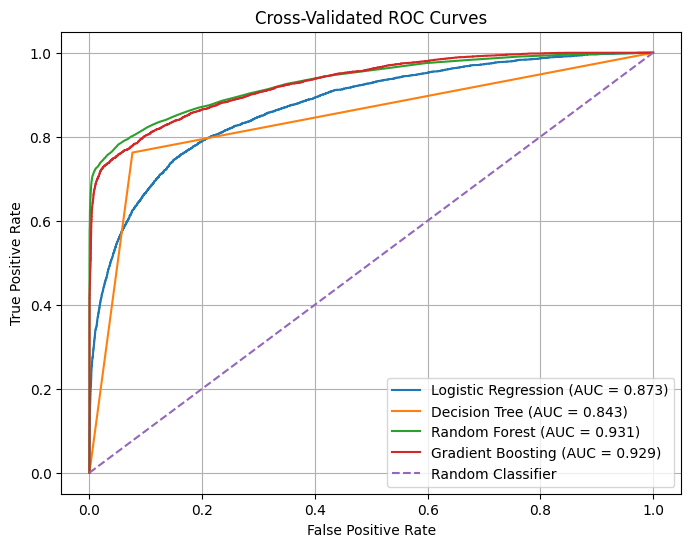

In [64]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for model_name, model in depth_models.items():
    oof_probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    fpr, tpr, _ = roc_curve(y_train, oof_probabilities)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Cross-Validated ROC Curves")
plt.legend()
plt.grid()
plt.show()

The cross-validated ROC curves show that all four classifiers perform substantially better than the random-classifier reference line, indicating that each model can distinguish between default and non-default cases.

Random Forest has the highest cross-validated ROC AUC at 0.931, followed closely by Gradient Boosting at 0.929. Logistic Regression records a lower ROC AUC of 0.873, while Decision Tree has the lowest at 0.843. The close performance of Random Forest and Gradient Boosting suggests that both ensemble methods capture useful patterns in the borrower data, although Random Forest maintains a slightly higher overall ROC AUC.

These results are consistent with the cross-validation comparison table, where Random Forest also recorded the highest mean F1 score. The ROC curves therefore provide additional evidence that the ensemble models are able to distinguish default and non-default cases more effectively than the individual Decision Tree and Logistic Regression models in this analysis.

## Comparing Feature Importance Across Models

To compare the features used by the four classifiers on the same basis, we will use permutation importance. Instead of relying on model-specific measures such as tree feature importance or Logistic Regression coefficients, permutation importance measures how much model performance changes when the values of a feature are randomly shuffled. We will calculate this within the cross-validation folds using each fold's validation data, then average the importance across the five folds. This keeps the test set untouched and provides a comparable feature-importance measure across all four classifiers.

In [65]:
from sklearn.inspection import permutation_importance

feature_importance_results = []

for model_name, model in depth_models.items():
    fold_importances = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        model.fit(X_fold_train, y_fold_train)

        importance = permutation_importance(
            model,
            X_fold_val,
            y_fold_val,
            scoring="roc_auc",
            n_repeats=5,
            random_state=42,
            n_jobs=-1
        )

        fold_importances.append(importance.importances_mean)

    mean_importance = np.mean(fold_importances, axis=0)

    for feature, importance in zip(X_train.columns, mean_importance):
        feature_importance_results.append({
            "Model": model_name,
            "Feature": feature,
            "Importance": importance
        })

feature_importance_df = pd.DataFrame(feature_importance_results)

display(
    feature_importance_df
    .sort_values(["Model", "Importance"], ascending=[True, False])
    .groupby("Model")
    .head(10)
    .round(4)
)

,Model,Feature,Importance
31,Decision Tree,renter_burden,0.1361
23,Decision Tree,loan_grade,0.1200
21,Decision Tree,person_income,0.0640
22,Decision Tree,person_emp_length,0.0260
26,Decision Tree,loan_percent_income,0.0241
36,Decision Tree,loan_intent_HOMEIMPROVEMENT,0.0208
24,Decision Tree,loan_amnt,0.0146
25,Decision Tree,loan_int_rate,0.0124
34,Decision Tree,person_home_ownership_RENT,0.0116
20,Decision Tree,person_age,0.0116


<u>What We Learned from the above result</u>

The permutation importance results show that some features are consistently useful across the four classification models, while the exact importance of each feature varies between models. `renter_burden` is among the most important features for Logistic Regression, Decision Tree, and Gradient Boosting, while `loan_grade` is consistently important across all four models. `person_income` and `loan_percent_income` also appear among the more important features across several models.

The differences between the models show that they do not rely on the available information in exactly the same way. Logistic Regression places relatively high importance on `renter_burden` and `loan_grade`, while the tree-based models distribute importance differently across features. Random Forest places `loan_grade`, `person_income`, and `renter_burden` among its most important features.

Overall, the comparison suggests that loan characteristics, borrower income, and the interaction between loan burden and renting status contain useful information for distinguishing default from non-default cases. The consistency of some features across different modelling approaches also provides additional evidence that these variables contain meaningful predictive information in this dataset.

## **<u>Prediction Timing Assumption</u>**

For this project, we treat the variables in the dataset as information available when the default-risk prediction is made. In particular, `loan_grade` is treated as an existing loan characteristic rather than the future outcome we are trying to predict. A borrower can be assessed and assigned a loan grade before the eventual repayment outcome is known. Therefore, the presence and importance of `loan_grade` in the model is not by itself considered target leakage.

The target variable, `loan_status`, represents the eventual default outcome and is therefore kept separate from the predictors. This assumption allows the models to use the recorded loan characteristics to assess the risk of default.

In [66]:
notebook_end_time = time.perf_counter()

total_runtime = notebook_end_time - notebook_start_time

print(f"Total notebook runtime: {total_runtime / 60:.2f} minutes")

Total notebook runtime: 5.64 minutes
